# Retail Decision-Support Recommender System

### **Master Thesis Project** – Internal recommender system for an offline retail store selling building materials / renovation products.  
#### The system uses historical point-of-sale transaction data (2022–2025) to discover product relationships, cross-selling opportunities, and buying patterns, then uses an LLM layer to translate analytical outputs into actionable business insights for non-technical managers.

----

# 1. IMPORT OF LIBRARIES

In [344]:
import pandas as pd
import glob
import seaborn as sns
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 2. DATA LOADING

In [345]:
# Find all CSV files for the years 2022-2025 in the directory
csv_files = glob.glob('data/raw/*-202*.csv')
print(f"Loading files: {csv_files}")

df_list = []
for file in csv_files:
    temp_df = pd.read_csv(file, encoding= "cp1250") # the problem was to apply correct decoding since file consist of dataset in polish
    df_list.append(temp_df)

# Concatenate all 8 files into a single DataFrame
df = pd.concat(df_list, ignore_index=True)

Loading files: ['data/raw/2-2022.csv', 'data/raw/2-2023.csv', 'data/raw/2-2024.csv', 'data/raw/2-2025.csv', 'data/raw/1-2024.csv', 'data/raw/1-2025.csv', 'data/raw/1-2022.csv', 'data/raw/1-2023.csv']


In [346]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152907 entries, 0 to 152906
Data columns (total 17 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   #                        152907 non-null  int64  
 1   Ilość magazynowa         152907 non-null  object 
 2   Wartość nabycia          152907 non-null  object 
 3   Wartość sprzedaży        152907 non-null  object 
 4   Nazwa kontrahenta        152907 non-null  object 
 5   Skrot nazwy kontrahenta  152867 non-null  object 
 6   Indeks                   152899 non-null  object 
 7   Nazwa                    152899 non-null  object 
 8   Data nabycia             152899 non-null  object 
 9   Nr dok. obrotowego       152899 non-null  object 
 10  Data sprzedaży           152899 non-null  object 
 11  Nr faktury               152899 non-null  object 
 12  Operator                 152899 non-null  object 
 13  Forma płatności          152899 non-null  object 
 14  Zysk

In [347]:
df.shape

(152907, 17)

In [348]:
df.columns.values

array(['#', 'Ilość magazynowa', 'Wartość nabycia', 'Wartość sprzedaży',
       'Nazwa kontrahenta', 'Skrot nazwy kontrahenta', 'Indeks', 'Nazwa',
       'Data nabycia', 'Nr dok. obrotowego', 'Data sprzedaży',
       'Nr faktury', 'Operator', 'Forma płatności', 'Zysk', 'Narzut',
       'Marża'], dtype=object)

In [349]:
df.head()

,#,Ilość magazynowa,Wartość nabycia,Wartość sprzedaży,Nazwa kontrahenta,Skrot nazwy kontrahenta,Indeks,Nazwa,Data nabycia,Nr dok. obrotowego,Data sprzedaży,Nr faktury,Operator,Forma płatności,Zysk,Narzut,Marża
0,1,"1,00","0,06","0,11",CENTRUM INFORMATYKI ZETO SPOLKA AKCYJNA,ZETO,5959000000008,TIKKURILLA-PIGMENT CW CZARNY S(SS),2022-10-06 00:00:00.0,WZ/a/22/012545,2022-10-06 00:00:00.0,F/a/22/03719,Roszko Barbara,gotówka,1023.0,"0,05","83,33"
1,2,"1,00","0,06","0,11",CENTRUM INFORMATYKI ZETO SPOLKA AKCYJNA,ZETO,5959000000008,TIKKURILLA-PIGMENT CW CZARNY S(SS),2022-11-15 00:00:00.0,WZ/a/22/014070,2022-11-15 00:00:00.0,F/a/22/04198,Żmurda Paweł,gotówka,1023.0,"0,05","83,33"
2,3,"1,00","0,06","0,12",SPRZEDAZ FISKALNA,SPRZEDAZ FISKALNA,5959000000001,TIKKURILLA-PIGMENT YX ZOLTY TL. (YO),2022-08-30 00:00:00.0,WZ/a/22/010788,2022-08-30 00:00:00.0,Pg/a/22/007233,Roszko Barbara,gotówka,1.0,"0,06","100,00"
3,4,"1,00","0,06","0,12",SPRZEDAZ FISKALNA,SPRZEDAZ FISKALNA,5959000000001,TIKKURILLA-PIGMENT YX ZOLTY TL. (YO),2022-09-01 00:00:00.0,WZ/a/22/010944,2022-09-01 00:00:00.0,Pg/a/22/007315,Żmurda Paweł,karta płatnicza,1.0,"0,06","100,00"
4,5,"1,00","0,06","0,12",XELOX FINANSE SPÓŁKA JAWNA JACEK I BEATA KLIMIUK,XELOX FINANSE SP. J. JACEK I BEATA KLIMIUK,5959000000001,TIKKURILLA-PIGMENT YX ZOLTY TL. (YO),2022-09-12 00:00:00.0,WZ/a/22/011366,2022-09-12 00:00:00.0,F/./22/00579,Roszko Barbara,przelew,91567.0,"0,06","100,00"


In [350]:
df.tail()

,#,Ilość magazynowa,Wartość nabycia,Wartość sprzedaży,Nazwa kontrahenta,Skrot nazwy kontrahenta,Indeks,Nazwa,Data nabycia,Nr dok. obrotowego,Data sprzedaży,Nr faktury,Operator,Forma płatności,Zysk,Narzut,Marża
152902,22063,"950,00","13.300,00","13.575,50",BENMAR Spółka z o.o.,BENMAR -POPIELUSZKI,MAPEI-PLYT-25,MAPEI GLAZURNIK ZAPRAWA KLEJOWA DO PLYTEK 25KG...,2023-04-06 00:00:00.0,WZ/a/23/003867,2023-04-06 00:00:00.0,F/a/23/01064,Marek Kosikowski,przelew,381.0,"275,50","2,07"
152903,22064,"95,50","11.610,89","14.112,99",ŁASZKIEWICZ JOANNA,ŁASZKIEWICZ JOANNA,TA977-1400000,"TUBADZIN TER.TORANO WHITE 79,8X79,8 LAPPATO GAT.I",2023-05-10 00:00:00.0,WZ/a/23/005086,2023-05-10 00:00:00.0,F/./23/00246,Hutnik Andrzej,przelew,96569.0,"2.502,10","21,55"
152904,22065,"150,00","14.377,50","16.305,00",APARTAMENTY ROGOWSKI REMIGIUSZ SPÓŁKA KOMANDYTOWA,APARTAMENTY ROGOWSKI REMIGIUSZ SPÓŁKA KOMANDYTOWA,MAPEI-NIVOPL5,MAPEI ZAPRAWA KLEJOWA ULTRALITE S1 BIAŁY 15KG,2023-04-19 00:00:00.0,WZ/a/23/004253,2023-04-19 00:00:00.0,F/a/23/01173,Żmurda Paweł,przelew,95344.0,"1.927,50","13,41"
152905,22066,"850,00","31.212,50","32.623,00",BENMAR Spółka z o.o.,BENMAR -POPIELUSZKI,MAPEI-P9-ZW,MAPEI ZAPRAWA KLEJOWA ADESILEX P9 ...25KG (pal...,2023-04-05 00:00:00.0,WZ/a/23/003825,2023-04-05 00:00:00.0,F/a/23/01053,Żmurda Paweł,przelew,381.0,"1.410,50","4,52"
152906,22067,"72.611,0228","2.560.698,26","3.058.401,96",Razem:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"497.703,70","19,44"


# 2. DATA CLEANING & STANDARDISATION

In [351]:
# Translate Polish column names to English for code readability and standardization
col_mapping = {
    '#': 'RowID',
    'Ilość magazynowa': 'Quantity',
    'Wartość nabycia': 'PurchaseValue',
    'Wartość sprzedaży': 'SalesValue',
    'Nazwa kontrahenta': 'CustomerName',
    'Skrot nazwy kontrahenta': 'CustomerShortName',
    'Indeks': 'ProductID',
    'Nazwa': 'ProductName',
    'Data nabycia': 'PurchaseDate',
    'Nr dok. obrotowego': 'DocNumber',
    'Data sprzedaży': 'SaleDate',
    'Nr faktury': 'InvoiceID',
    'Operator': 'Operator',
    'Forma płatności': 'PaymentMethod',
    'Zysk': 'Profit',
    'Narzut': 'Markup',
    'Marża': 'Margin'
}
df.rename(columns=col_mapping, inplace=True)

In [352]:
# Fix Polish number formatting (e.g., '1 750,00' or '1.750,00' -> 1750.00) and change to float type 
numeric_cols = ['Quantity', 'PurchaseValue', 'SalesValue', 'Markup', 'Margin']
for col in numeric_cols:
    if df[col].dtype == 'object':
        # 1. Remove thousands separator (dots)
        # 2. Remove spaces
        # 3. Replace decimal comma with dot
        df[col] = (df[col].astype(str)
                   .str.replace('.', '', regex=False)
                   .str.replace(' ', '', regex=False)
                   .str.replace(',', '.', regex=False)
                   .astype(float))


In [353]:
# Convert dates to proper datetime objects
df['SaleDate'] = pd.to_datetime(df['SaleDate'], errors='coerce')
df['PurchaseDate'] = pd.to_datetime(df['PurchaseDate'], errors='coerce')

In [354]:
df.isna().sum()

RowID                 0
Quantity              0
PurchaseValue         0
SalesValue            0
CustomerName          0
CustomerShortName    40
ProductID             8
ProductName           8
PurchaseDate          8
DocNumber             8
SaleDate              8
InvoiceID             8
Operator              8
PaymentMethod         8
Profit                8
Markup                0
Margin                0
dtype: int64

In [355]:
# dropping the column that has data that it overlapping with another column CustomerName which does not have missing values
df = df.drop('CustomerShortName', axis=1)

In [356]:
# it looks like CustomerShortName can be dropped as it has missing values and similar ino as CustomerName - no need to keep both variables

In [357]:
# Drop rows where critical transaction identifiers are entirely missing
# (There were 8 completely corrupted rows found in the raw data)
df.dropna(subset=['SaleDate', 'InvoiceID', 'ProductID'], inplace=True)

In [358]:
df['Quantity'].value_counts()

Quantity
1.0000      99836
2.0000      21343
3.0000       6932
4.0000       5048
5.0000       2928
            ...  
10.6624         1
256.0000        1
1.5500          1
1.9700          1
95.5000         1
Name: count, Length: 1416, dtype: int64

In [359]:
df['PurchaseValue'].value_counts()

PurchaseValue
26.60       1158
1.56         589
1.46         517
2.00         389
1.52         385
            ... 
550.80         1
544.82         1
665.04         1
608.64         1
31212.50       1
Name: count, Length: 20777, dtype: int64

In [360]:
df['SalesValue'].value_counts()

SalesValue
4.07        2096
16.26       1854
6.50        1717
9.76        1612
8.13        1601
            ... 
494.64         1
499.75         1
500.32         1
500.86         1
32623.00       1
Name: count, Length: 24126, dtype: int64

In [361]:
df['CustomerName'].value_counts()

CustomerName
SPRZEDAZ FISKALNA                                                         64031
REDIL JACEK RUTKOWSKI                                                      1537
FINEDOR SPÓŁKA Z OGRANICZONĄ ODPOWIEDZIALNOŚCIĄ                            1346
BENMAR Spółka z o.o.                                                       1247
FIRMA BUDOWLANA ARSON ELWIRA SUPERSON                                      1238
                                                                          ...  
PRAMSO SPÓŁKA Z OGRANICZONĄ ODPOWIEDZIALNOŚCIĄ                                1
PRACOWNIA PROJEKTOWA I REALIZACJI INWESTYCJI "AJAKA" inż JANUSZ KARSKI        1
FIRMA PRYWATNA MEFISTO ANDRZEJ WASILEWSKI                                     1
WIŚNIOWY SAD ANDRZEJ SZEREMETA                                                1
REM KRZYSZTOF NIEDŹWIECKI                                                     1
Name: count, Length: 5140, dtype: int64

In [362]:
df['ProductID'].value_counts()

ProductID
PR1-000000000    1003
8876532223666     985
MAPEI-KERA-25     887
MAPEI-P9-ZW       828
5904006071622     708
                 ... 
ZEU 3210            1
100653500101        1
TA53655             1
1001050-01-01       1
OP661-064-1         1
Name: count, Length: 13827, dtype: int64

In [363]:
df['Operator'].value_counts()

Operator
Żmurda Paweł        49294
Marek Kosikowski    38682
Hutnik Andrzej      37894
Roszko Barbara      26130
Karpienia Artur       878
Galińska Jolanta       21
Name: count, dtype: int64

In [364]:
df['Profit'].value_counts()

Profit
1.0        64031
92282.0     1389
95607.0     1346
381.0       1247
89147.0     1238
           ...  
64787.0        1
97445.0        1
97526.0        1
82041.0        1
49857.0        1
Name: count, Length: 5172, dtype: int64

In [365]:
df['Markup'].value_counts()

Markup
0.00       495
2.52       282
2.07       282
1.63       280
2.60       268
          ... 
224.17       1
111.93       1
136.11       1
159.14       1
1410.50      1
Name: count, Length: 15962, dtype: int64

In [366]:
df['Margin'].value_counts()

Margin
 12.31     1111
 11.11      743
 7.69       741
 25.00      664
 10.77      628
           ... 
 131.56       1
 50.88        1
 322.92       1
 137.96       1
-4.37         1
Name: count, Length: 13760, dtype: int64

# 3. EXPLORATORY DATA ANALYSIS (EDA)

In [367]:
columns = ["Quantity","PurchaseValue","SalesValue","Profit","Markup","Margin"]
for column in columns:
    print(f"{df[column].describe().round(2)}\n")

count    152899.00
mean          4.20
std          31.03
min        -595.20
25%           1.00
50%           1.00
75%           2.00
max        6000.00
Name: Quantity, dtype: float64

count    152899.00
mean        140.13
std         623.86
min      -17591.14
25%           7.12
50%          19.94
75%          60.15
max       55732.32
Name: PurchaseValue, dtype: float64

count    152899.00
mean        168.91
std         729.97
min           0.04
25%          11.02
50%          27.57
75%          79.12
max       62244.00
Name: SalesValue, dtype: float64

count    152899.00
mean      45106.14
std       44343.54
min           1.00
25%           1.00
50%       40161.00
75%       92460.00
max       99049.00
Name: Profit, dtype: float64

count    152899.00
mean         28.78
std         183.61
min      -10544.17
25%           3.07
50%           6.90
75%          16.85
max       36935.14
Name: Markup, dtype: float64

count    152899.00
mean         62.28
std         865.90
min         -99.46
2

* Visualizing all the numeric values using boxplots

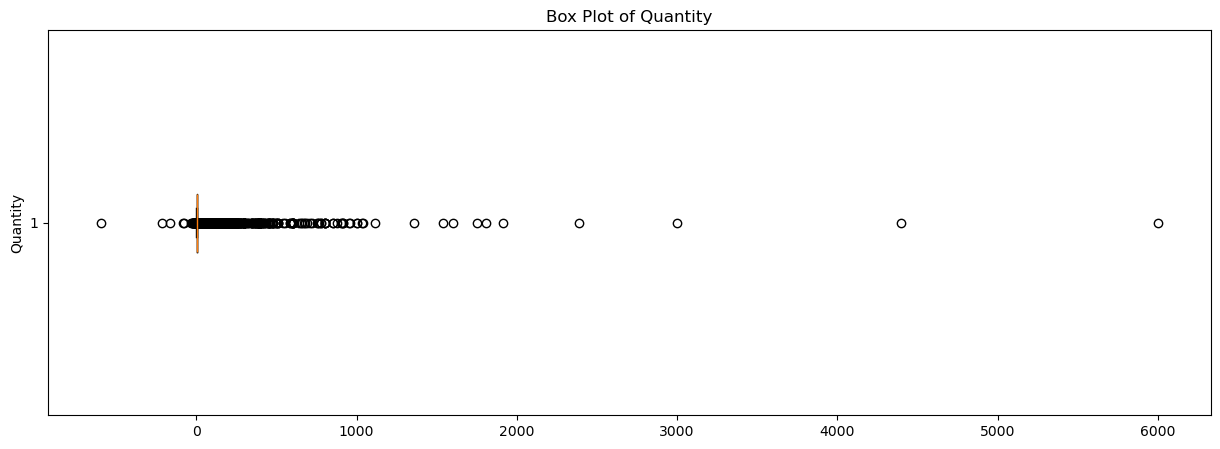

In [368]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['Quantity'], vert=False)
plt.title('Box Plot of Quantity')
plt.ylabel('Quantity')
plt.savefig('plots/box_plot_of_quantity.png')
plt.show()
plt.close()

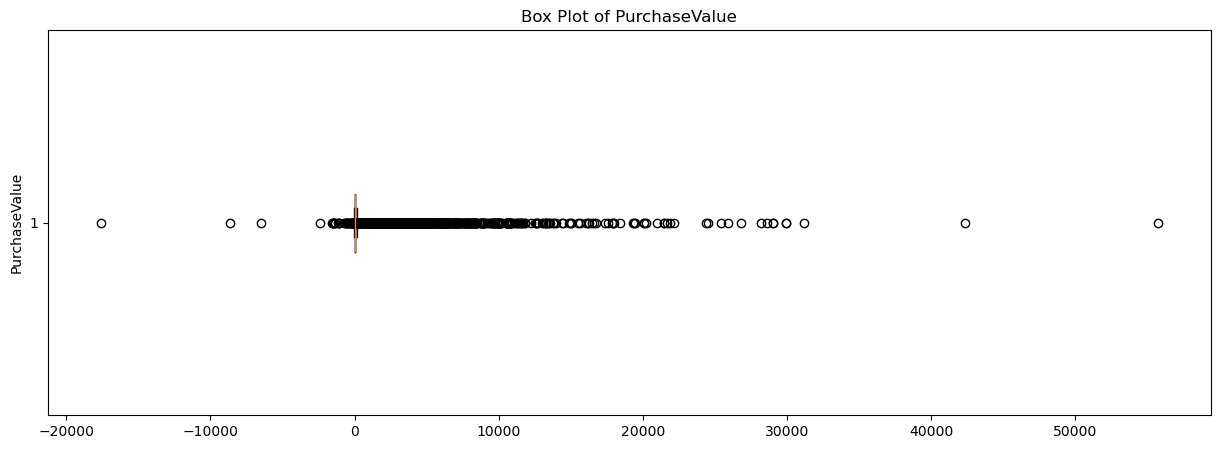

In [369]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['PurchaseValue'], vert=False)
plt.title('Box Plot of PurchaseValue')
plt.ylabel('PurchaseValue')
plt.savefig('plots/box_plot_of_purchase_values.png')
plt.show()
plt.close()

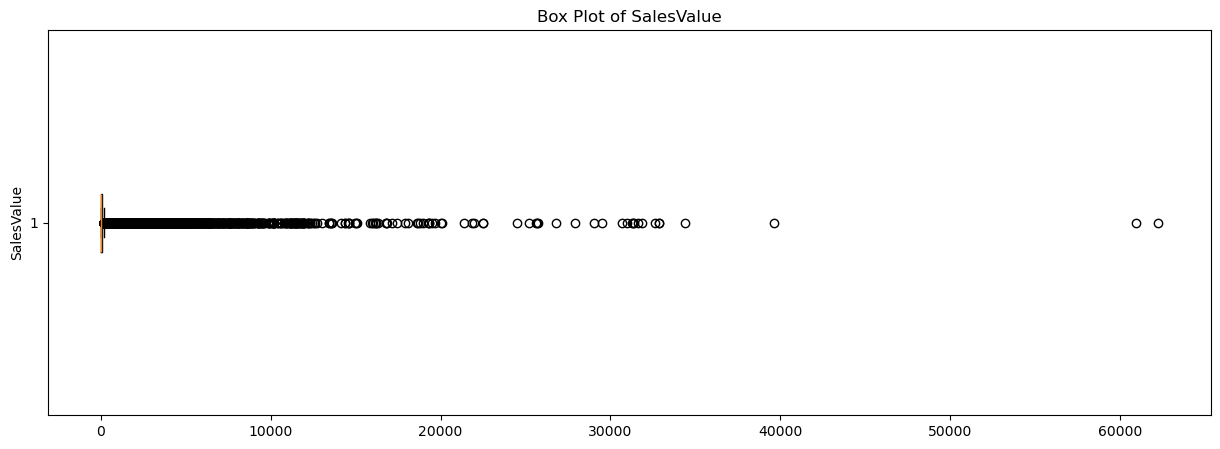

In [370]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['SalesValue'], vert=False)
plt.title('Box Plot of SalesValue')
plt.ylabel('SalesValue')
plt.savefig('plots/box_plot_of_sales_values.png')
plt.show()
plt.close()

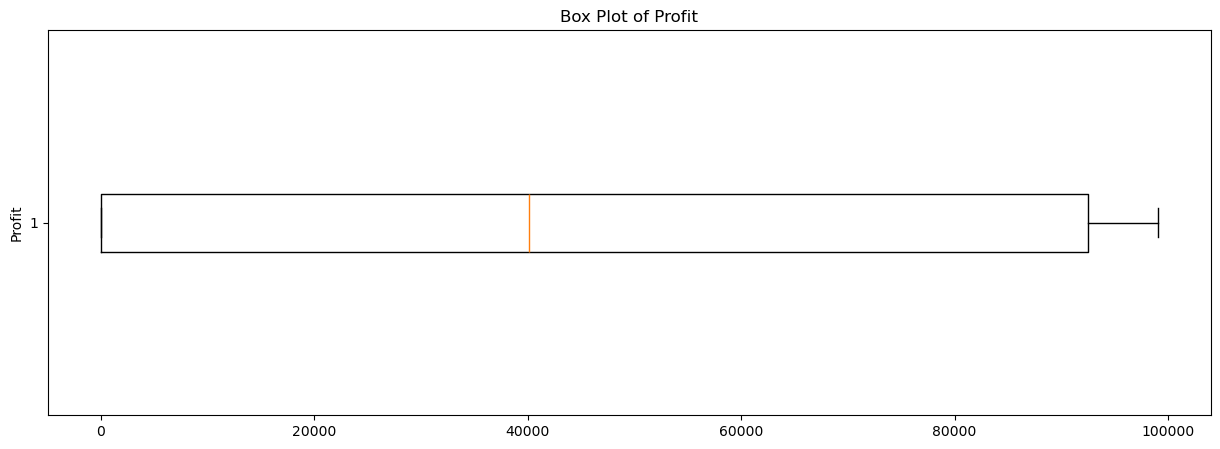

In [371]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['Profit'], vert=False)
plt.title('Box Plot of Profit')
plt.ylabel('Profit')
plt.savefig('plots/box_plot_of_profit.png')
plt.show()
plt.close()

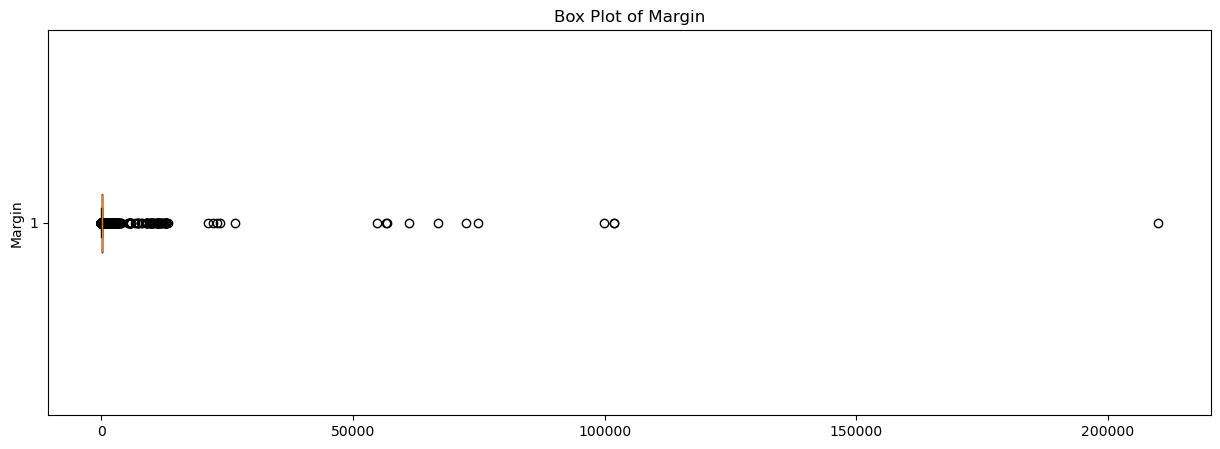

In [372]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['Margin'], vert=False)
plt.title('Box Plot of Margin')
plt.ylabel('Margin')
plt.savefig('plots/box_plot_of_margin.png')
plt.show()
plt.close()

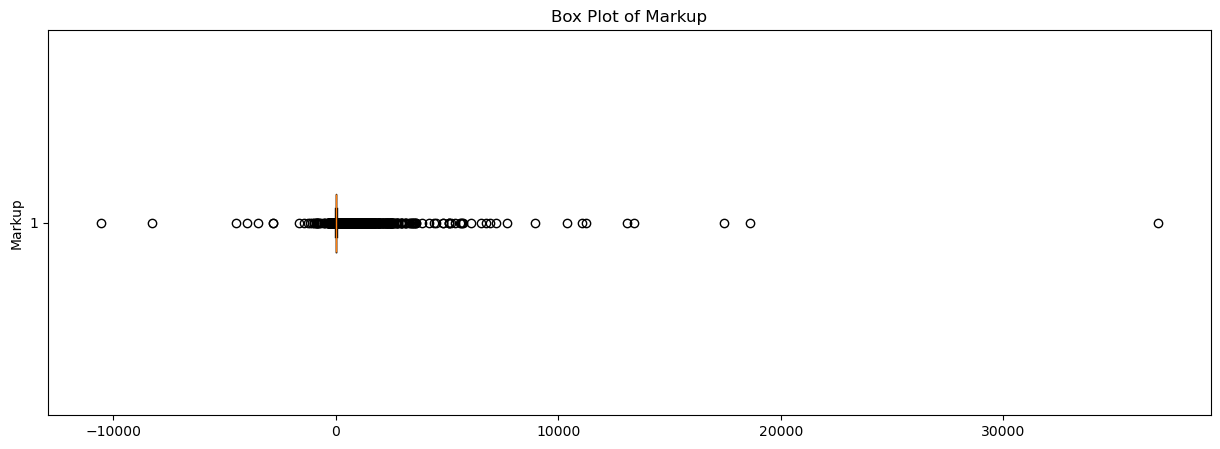

In [373]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))

plt.boxplot(df['Markup'], vert=False)
plt.title('Box Plot of Markup')
plt.ylabel('Markup')
plt.savefig('plots/box_plot_of_markup.png')
plt.show()
plt.close()

*  Top 10 Products by Total Quantity Sold

/var/folders/gm/vll5hdf55pq69ynclc1r1f0m0000gn/T/ipykernel_76881/3197133162.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')


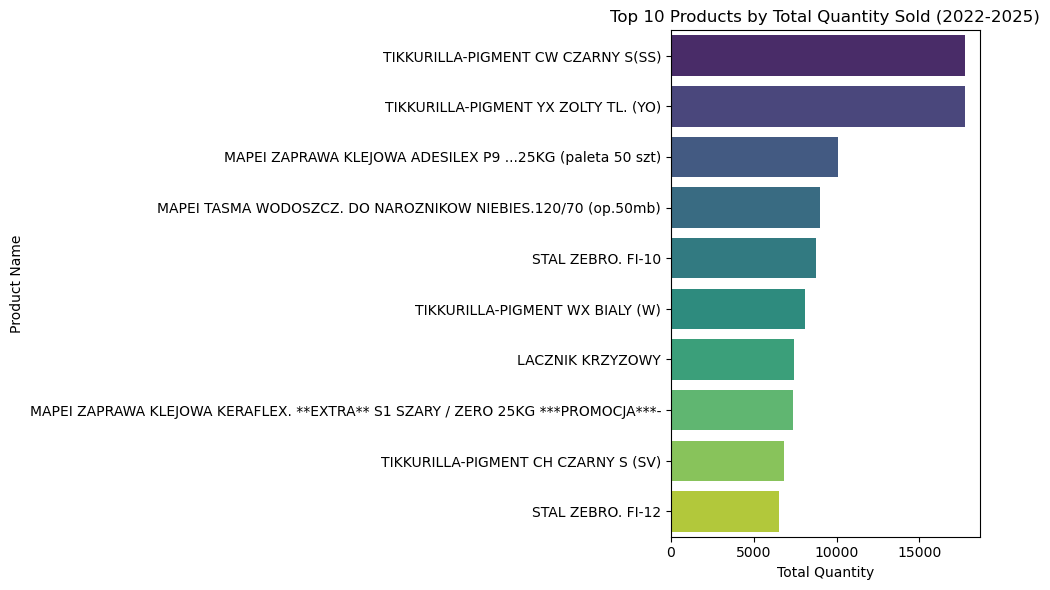

In [374]:
plt.figure(figsize=(10, 6))
top_products = df.groupby('ProductName')['Quantity'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis')
plt.title('Top 10 Products by Total Quantity Sold (2022-2025)')
plt.xlabel('Total Quantity')
plt.ylabel('Product Name')
plt.tight_layout()
plt.savefig('plots/eda_top_products.png')
plt.show()
plt.close()

* Top 10 Known Customers by Sales Value

/var/folders/gm/vll5hdf55pq69ynclc1r1f0m0000gn/T/ipykernel_76881/2576711993.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_customers.values, y=top_customers.index, palette='magma')


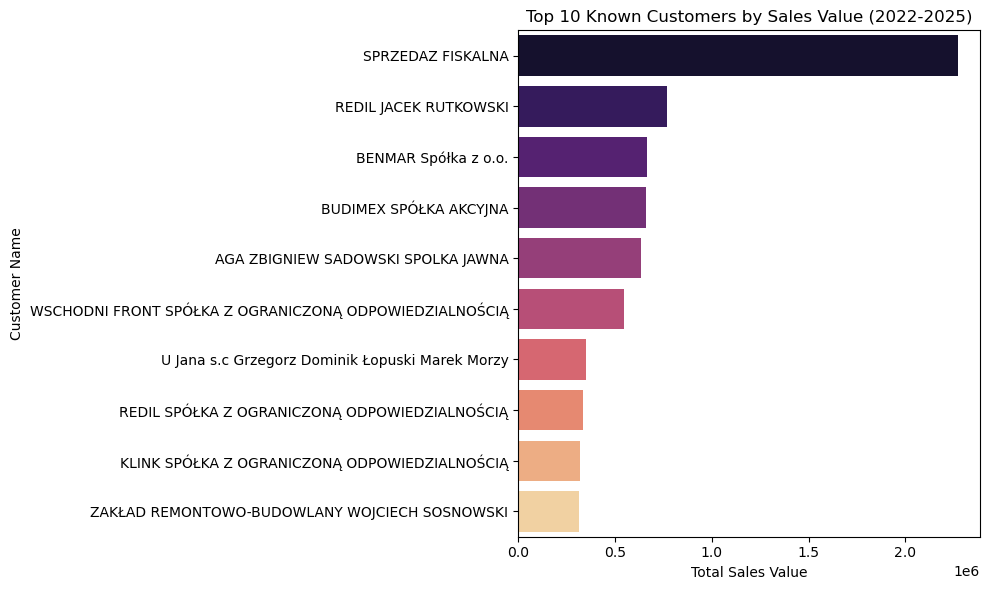

In [375]:
plt.figure(figsize=(10, 6))
top_customers = df.groupby('CustomerName')['SalesValue'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_customers.values, y=top_customers.index, palette='magma')
plt.title('Top 10 Known Customers by Sales Value (2022-2025)')
plt.xlabel('Total Sales Value')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.savefig('plots/eda_top_customers_all.png')
plt.show()
plt.close()

---
# * what percentage of total revenue comes from B2B vs. B2C to give managers context. -> add the plot here
--- 

/var/folders/gm/vll5hdf55pq69ynclc1r1f0m0000gn/T/ipykernel_76881/2163802792.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_customers.values, y=top_customers.index, palette='magma')


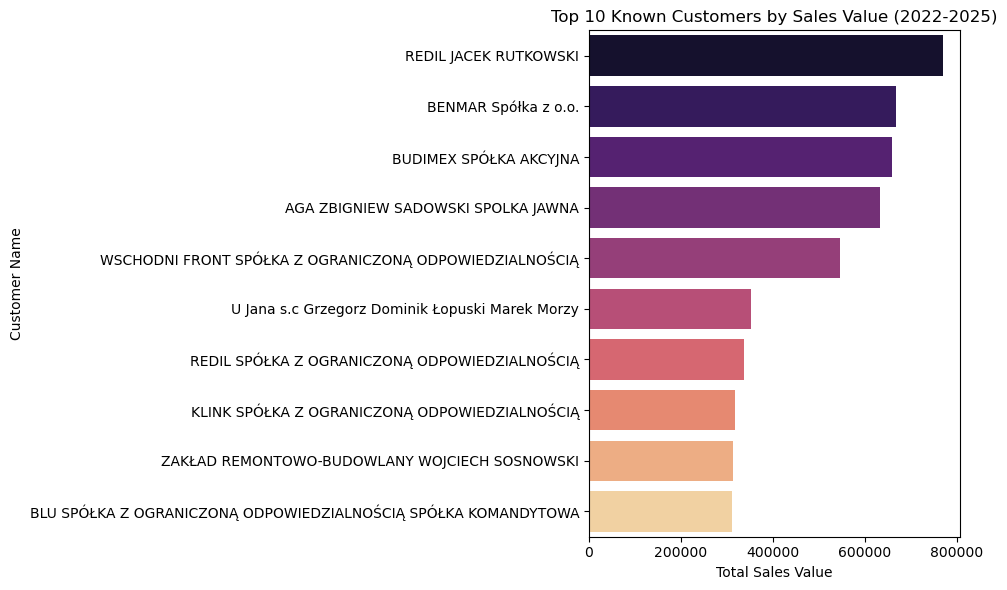

In [376]:
# Note: Filtering out 'SPRZEDAZ FISKALNA' as it represents all anonymous walk-in retail sales combined
plt.figure(figsize=(10, 6))
known_customers = df[df['CustomerName'] != 'SPRZEDAZ FISKALNA']
top_customers = known_customers.groupby('CustomerName')['SalesValue'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_customers.values, y=top_customers.index, palette='magma')
plt.title('Top 10 Known Customers by Sales Value (2022-2025)')
plt.xlabel('Total Sales Value')
plt.ylabel('Customer Name')
plt.tight_layout()
plt.savefig('plots/eda_top_customers.png')
plt.show()
plt.close()

* Sales Trend Over Time

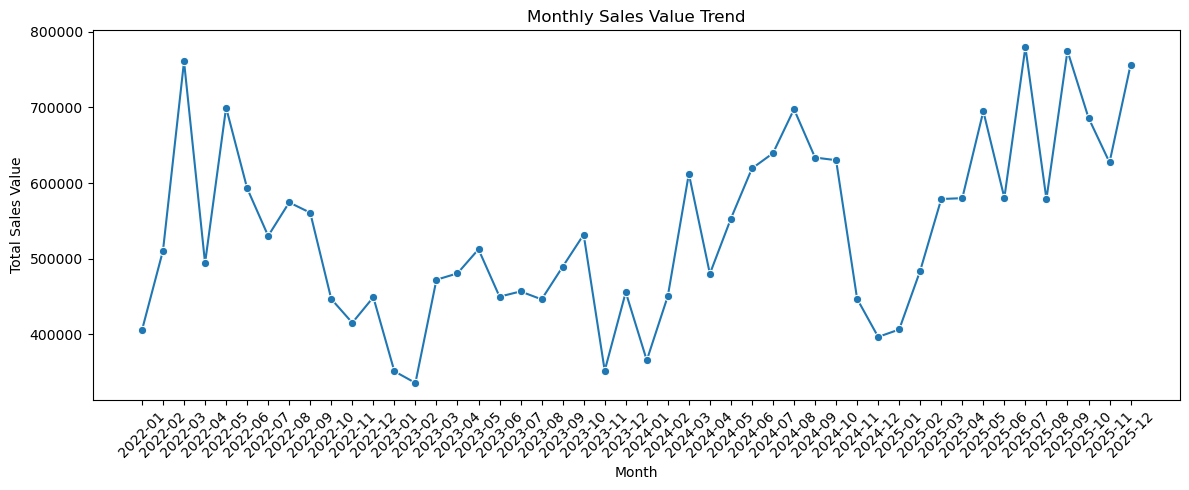

In [377]:
df['YearMonth'] = df['SaleDate'].dt.to_period('M')
monthly_sales = df.groupby('YearMonth')['SalesValue'].sum().reset_index()
monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_sales, x='YearMonth', y='SalesValue', marker='o')
plt.title('Monthly Sales Value Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('plots/eda_monthly_sales.png')
plt.show()
plt.close()

# 3. FEATURE ENGINEERING


* outlier handling

In [378]:
# A. Remove Negative Values (Returns and Errors)
df = df[(df['Quantity'] > 0) & (df['SalesValue'] > 0)].copy()

# B. Winsorize (Cap) Extreme Positive Outliers at the 99th percentile
# We do this for Quantity and SalesValue to prevent wholesale/B2B purchases 
# from dominating the Collaborative Filtering weights.
q_99 = df['Quantity'].quantile(0.99)
v_99 = df['SalesValue'].quantile(0.99)

df['Quantity'] = df['Quantity'].clip(upper=q_99)
df['SalesValue'] = df['SalesValue'].clip(upper=v_99)

print(f"Data shape after removing negatives: {df.shape}")
print(f"Capped Quantity at: {q_99:.2f}")
print(f"Capped SalesValue at: {v_99:.2f}")

Data shape after removing negatives: (152836, 17)
Capped Quantity at: 50.00
Capped SalesValue at: 2090.96


* RFM segmentation preparation

In [379]:
# Exclude anonymous sales for personalized segmentation
known_customers = df[df['CustomerName'] != 'SPRZEDAZ FISKALNA'].copy()

# Calculate Reference Date for Recency (1 day after the latest transaction)
reference_date = known_customers['SaleDate'].max() + pd.Timedelta(days=1)

# Group by CustomerName to calculate RFM
rfm = known_customers.groupby('CustomerName').agg({
    'SaleDate': lambda x: (reference_date - x.max()).days,  # Recency
    'InvoiceID': 'nunique',                                 # Frequency
    'SalesValue': 'sum'                                     # Monetary
}).rename(columns={
    'SaleDate': 'Recency', 
    'InvoiceID': 'Frequency', 
    'SalesValue': 'Monetary'
})

# Standardize the RFM values for K-Means
scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm), 
                          index=rfm.index, 
                          columns=rfm.columns)

print("\nRFM Scaled Preview:")
print(rfm_scaled.head())


RFM Scaled Preview:
                              Recency  Frequency  Monetary
CustomerName                                              
!GAŁECKI II MARIUSZ GAŁECKI  0.180717  -0.126132 -0.175535
" BIUREX " DUŚ RENATA       -0.523114  -0.203640 -0.178232
" DEKA" Dariusz Kierski      0.608447  -0.203640 -0.184818
" LENZ " MATEUSZ LENZ        0.746498  -0.203640 -0.181302
" U Jana " Marek Morzy       0.950179   0.571434  0.522873


* K-Means Customer Segmentation


In [ ]:
from sklearn.cluster import KMeans

# --- Elbow Method: find optimal number of customer segments ---
inertias = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertias, marker='o')
plt.title('Elbow Method – Optimal Number of Customer Segments')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_range))
plt.tight_layout()
plt.savefig('plots/kmeans_elbow.png')
plt.show()
plt.close()

# --- Fit Final K-Means Model (K=4 is standard for retail RFM segmentation) ---
OPTIMAL_K = 4
kmeans = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init=10)
rfm['Segment'] = kmeans.fit_predict(rfm_scaled)

# --- Assign business-friendly labels based on combined RFM score ---
# Higher frequency + monetary + lower recency (days since purchase) = better segment
seg_stats = rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean()
seg_stats['Score'] = (
    seg_stats['Frequency'].rank() +
    seg_stats['Monetary'].rank() -
    seg_stats['Recency'].rank()   # lower recency value = more recent = better
)
seg_sorted = seg_stats.sort_values('Score', ascending=False).index.tolist()
label_map = {
    seg_sorted[0]: 'Champions',
    seg_sorted[1]: 'High-Value',
    seg_sorted[2]: 'Regular',
    seg_sorted[3]: 'Inactive',
}
rfm['SegmentLabel'] = rfm['Segment'].map(label_map)

print("Cluster Summary (mean RFM values per segment):")
print(seg_stats[['Recency', 'Frequency', 'Monetary']].round(1))
print("\nCustomer Segment Counts:")
print(rfm['SegmentLabel'].value_counts())


* USER-ITEM INTERACTION MATRIX (For Collaborative Filtering)

In [ ]:
# Filter to customers with at least 2 invoices before building the CF matrix.
# Customers with only a single invoice produce near-zero similarity signals
# and inflate sparsity without contributing meaningful co-purchase patterns.
MIN_INVOICES = 2
invoice_counts    = known_customers.groupby('CustomerName')['InvoiceID'].nunique()
active_customers  = invoice_counts[invoice_counts >= MIN_INVOICES].index
cf_customers      = known_customers[known_customers['CustomerName'].isin(active_customers)]

print(f"Customers with >= {MIN_INVOICES} invoices: {len(active_customers)} retained out of {invoice_counts.shape[0]} total")

# Rows = Customers, Columns = Products, Values = Total Quantity (capped)
user_item_matrix = cf_customers.pivot_table(
    index='CustomerName',
    columns='ProductName',
    values='Quantity',
    aggfunc='sum',
    fill_value=0
)

print(f"\nUser-Item Matrix shape (Customers x Products): {user_item_matrix.shape}")



User-Item Matrix shape (Customers x Products): (5139, 12462)


* BOOLEAN BASKET MATRIX (For Association Rules)

In [384]:
def build_basket_matrix(data):
    """
    Transforms the transaction data into a Boolean matrix for Apriori.
    Rows = Invoices, Columns = Products, Values = 1 or 0
    """
    # Group by Invoice and Product, summing the quantity
    basket = data.groupby(['InvoiceID', 'ProductName'])['Quantity'] \
                 .sum().unstack().reset_index().fillna(0)
    
    basket.set_index('InvoiceID', inplace=True)
    
    # Convert quantities to Boolean (1 if bought, 0 if not)
    # Using boolean types directly is significantly faster and uses less memory
    basket_bool = basket.map(lambda x: bool(x > 0))
    return basket_bool

In [385]:
print("Splitting data into B2C (Walk-ins) and B2B (Contractors)...")
b2c_data = df[df['CustomerName'] == 'SPRZEDAZ FISKALNA']
b2b_data = df[df['CustomerName'] != 'SPRZEDAZ FISKALNA']

# Build the matrices
b2c_basket = build_basket_matrix(b2c_data)
b2b_basket = build_basket_matrix(b2b_data)

print(f"B2C Basket Shape: {b2c_basket.shape[0]} invoices, {b2c_basket.shape[1]} unique products")
print(f"B2B Basket Shape: {b2b_basket.shape[0]} invoices, {b2b_basket.shape[1]} unique products")

Splitting data into B2C (Walk-ins) and B2B (Contractors)...
B2C Basket Shape: 35995 invoices, 4923 unique products
B2B Basket Shape: 18641 invoices, 12462 unique products


In [381]:
# # We use ALL data (including 'SPRZEDAZ FISKALNA') because Apriori only cares 
# # about what items were bought together on the same Invoice.
# basket = df.groupby(['InvoiceID', 'ProductName'])['Quantity'].sum().unstack().reset_index().fillna(0)
# basket.set_index('InvoiceID', inplace=True)

# # Convert quantities to Boolean (1 if bought, 0 if not)
# def encode_units(x):
#     return 1 if x > 0 else 0

# basket_matrix = basket.map(encode_units)

# print(f"Basket Matrix shape (Invoices x Products): {basket_matrix.shape}")

Basket Matrix shape (Invoices x Products): (54636, 13696)


# 4. EXPORT

In [382]:
# Save the consolidated, cleaned dataset for modeling
output_filename = 'data/preprocessed/cleaned_retail_data_2022_2025.csv'
df.to_csv(output_filename, index=False)
print(f"Data successfully cleaned and saved to {output_filename}")

Data successfully cleaned and saved to data/preprocessed/cleaned_retail_data_2022_2025.csv


In [386]:
# Save the matrices and RFM data for the modeling phase
rfm.to_csv('data/preprocessed/rfm_base.csv')
user_item_matrix.to_pickle('data/preprocessed/user_item_matrix.pkl') # Pickle is better for large matrices
b2c_basket.to_pickle('data/preprocessed/basket_matrix_b2c.pkl')
b2b_basket.to_pickle('data/preprocessed/basket_matrix_b2b.pkl')
print("\nPreprocessing complete. Matrices saved.")


Preprocessing complete. Matrices saved.
